<a href="https://colab.research.google.com/github/parmesanpizzoy/Trend-Analysis/blob/main/yolo_kendaraan_v8_v11.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Custom Object Detection Kendaraan: YOLOv8 vs YOLOv11

Kelas: `roda2` (motor/sepeda), `roda3` (bajaj/becak/tuk-tuk), `roda4` (mobil/bus/truk).

**Catatan penting tentang dataset:** `dataset_kendaraan.zip` hanya berisi gambar yang dikelompokkan per folder (`Train/Roda2`, `Train/Roda3`, `Train/Roda4`) dan `Testing/`. **Tidak ada file anotasi bounding box**, padahal object detection membutuhkannya.
Notebook ini membuat label awal secara otomatis (pseudo-labeling dengan YOLO COCO pretrained, kelasnya dipaksa mengikuti nama folder). Hasilnya cukup untuk menjalankan pipeline, tetapi **sebaiknya diperiksa/dikoreksi manual** (Roboflow, CVAT, atau LabelImg) agar akurasi bagus.

Alur: 1) setup, 2) siapkan data + auto-label, 3) latih YOLOv8 & YOLO11, 4) evaluasi & bandingkan, 5) prediksi gambar Testing.

In [ ]:
!pip install -q ultralytics pillow-avif-plugin pandas matplotlib pyyaml

## 1. Konfigurasi & ekstraksi dataset
Ubah `ZIP_PATH` jika lokasi zip berbeda. Semua hasil disimpan di folder `work_yolo` di samping file zip.

In [ ]:
import os, re, shutil, zipfile, random
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
try:
    import pillow_avif  # noqa: F401  (agar file .avif bisa dibaca)
except Exception:
    pass

# Memperbaiki ZIP_PATH agar menunjuk ke file di lingkungan Colab
ZIP_PATH = r"/content/dataset kendaraan.zip"
WORK = Path(ZIP_PATH).parent / "work_yolo"      # semua hasil (dataset YOLO, runs, prediksi) disimpan di sini
RAW = WORK / "raw"
YOLO_DIR = WORK / "yolo_dataset"

CLASS_NAMES = ["roda2", "roda3", "roda4"]
FOLDER2ID = {"roda2": 0, "roda3": 1, "roda4": 2}
SEED = 42
EXT = {".jpg", ".jpeg", ".png", ".webp", ".avif", ".bmp"}
random.seed(SEED); np.random.seed(SEED)

def find_root():
    if RAW.exists():
        for p in RAW.rglob("*"):
            if p.is_dir() and p.name.lower() in ("train", "training"):
                return p.parent
    return None

ROOT = find_root()
if ROOT is None:   # belum diekstrak / hasil ekstrak sebelumnya kosong -> ekstrak ulang
    if not os.path.exists(ZIP_PATH):
        raise FileNotFoundError(f"File zip tidak ditemukan: {ZIP_PATH}. Upload dulu atau ubah ZIP_PATH.")
    shutil.rmtree(RAW, ignore_errors=True)
    RAW.mkdir(parents=True)
    with zipfile.ZipFile(ZIP_PATH) as z:
        z.extractall(RAW)
    ROOT = find_root()
if ROOT is None:
    raise FileNotFoundError("Folder 'Train' tidak ada di dalam zip. Struktur yang ditemukan:\n" +
                            "\n".join(str(p.relative_to(RAW)) for p in list(RAW.rglob("*"))[:30]))

def subdir(name):
    return next(p for p in ROOT.iterdir() if p.is_dir() and p.name.lower().startswith(name))

TRAIN_DIR, TEST_DIR = subdir("train"), subdir("test")
print("Root dataset:", ROOT, "| Train:", TRAIN_DIR.name, "| Test:", TEST_DIR.name)

Root dataset: /content/work_yolo/raw/dataset kendaraan | Train: Train | Test: Testing


In [ ]:
def collect_items():
    train_items = []
    for d in sorted(TRAIN_DIR.iterdir()):
        if d.is_dir() and d.name.lower() in FOLDER2ID:
            for f in sorted(d.iterdir()):
                if f.suffix.lower() in EXT:
                    train_items.append((f, FOLDER2ID[d.name.lower()]))
    test_items = []
    for f in sorted(TEST_DIR.iterdir()):
        m = re.match(r"roda(\d)", f.stem.lower())      # roda22_1 -> roda2, roda33_1 -> roda3, ...
        if m and f.suffix.lower() in EXT and ("roda" + m.group(1)) in FOLDER2ID:
            test_items.append((f, FOLDER2ID["roda" + m.group(1)]))
    return train_items, test_items

train_items, test_items = collect_items()
print("Train:", pd.Series([CLASS_NAMES[c] for _, c in train_items]).value_counts().to_dict())
print("Test :", pd.Series([CLASS_NAMES[c] for _, c in test_items]).value_counts().to_dict())

Train: {'roda4': 17, 'roda3': 14, 'roda2': 12}
Test : {'roda3': 8, 'roda2': 5, 'roda4': 5}


## 2. Auto-label (pseudo-label) dengan model COCO pretrained
- `roda2` mengambil deteksi COCO *bicycle/motorcycle*
- `roda4` mengambil deteksi *car/bus/truck*
- `roda3` (bajaj, becak, dll. tidak ada di COCO) mengambil kendaraan terbesar yang terdeteksi
- Jika tidak ada deteksi, dipakai box cadangan (hampir seluruh gambar) dan ditandai `fallback` di laporan, **prioritaskan koreksi manual untuk yang ini**.

In [ ]:
from ultralytics import YOLO

teacher = YOLO("yolo11x.pt")   # model COCO sebagai "guru" untuk membuat label awal
ALLOWED = {0: {1, 3}, 1: {1, 2, 3, 5, 7}, 2: {2, 5, 7}}   # id COCO yang diterima per kelas
TEACHER_CONF = 0.25

def detect(img_path):
    r = teacher.predict(str(img_path), conf=TEACHER_CONF, verbose=False)[0]
    return [(int(b.cls), float(b.conf), b.xyxyn[0].tolist()) for b in r.boxes]

def xyxyn_to_yolo(b):
    x1, y1, x2, y2 = b
    return [(x1 + x2) / 2, (y1 + y2) / 2, x2 - x1, y2 - y1]

def auto_label(img_path, cls):
    dets = [d for d in detect(img_path) if d[0] in ALLOWED[cls]]
    if dets:
        if cls == 1:  # roda3: ambil objek terbesar saja
            dets = [max(dets, key=lambda d: (d[2][2] - d[2][0]) * (d[2][3] - d[2][1]))]
        return [(cls, *xyxyn_to_yolo(d[2])) for d in dets], "auto"
    return [(cls, 0.5, 0.5, 0.9, 0.9)], "fallback"

def to_jpg(src, dst):
    im = Image.open(src).convert("RGB")
    im.save(dst, quality=95)
    return im.size

def build_split(items, split, report):
    img_dir = YOLO_DIR / "images" / split
    lbl_dir = YOLO_DIR / "labels" / split
    img_dir.mkdir(parents=True, exist_ok=True); lbl_dir.mkdir(parents=True, exist_ok=True)
    for i, (src, cls) in enumerate(items):
        stem = f"{CLASS_NAMES[cls]}_{split}_{i:03d}"
        dst = img_dir / f"{stem}.jpg"
        to_jpg(src, dst)
        boxes, source = auto_label(dst, cls)
        with open(lbl_dir / f"{stem}.txt", "w") as f:
            for c, x, y, w, h in boxes:
                f.write(f"{c} {x:.6f} {y:.6f} {w:.6f} {h:.6f}\n")
        report.append(dict(file=dst.name, split=split, cls=CLASS_NAMES[cls], n_boxes=len(boxes), source=source, original=src.name))

def stratified_split(items, val_ratio=0.2):
    tr, va = [], []
    for c in range(len(CLASS_NAMES)):
        group = [it for it in items if it[1] == c]
        random.shuffle(group)
        n_val = max(1, round(len(group) * val_ratio))
        va += group[:n_val]; tr += group[n_val:]
    return tr, va

if YOLO_DIR.exists():
    shutil.rmtree(YOLO_DIR)
tr_items, va_items = stratified_split(train_items)
report = []
build_split(tr_items, "train", report)
build_split(va_items, "val", report)
build_split(test_items, "test", report)

report_df = pd.DataFrame(report)
report_df.to_csv(WORK / "label_report.csv", index=False)
print(report_df.groupby(["split", "cls"]).size().unstack(fill_value=0))
print("\nJumlah label fallback (perlu dicek manual):", int((report_df.source == "fallback").sum()), "dari", len(report_df))

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
cls    roda2  roda3  roda4
split                     
test       5      8      5
train     10     11     14
val        2      3      3

Jumlah label fallback (perlu dicek manual): 0 dari 61


path: /content/work_yolo/yolo_dataset
train: images/train
val: images/val
test: images/test
names:
  0: roda2
  1: roda3
  2: roda4



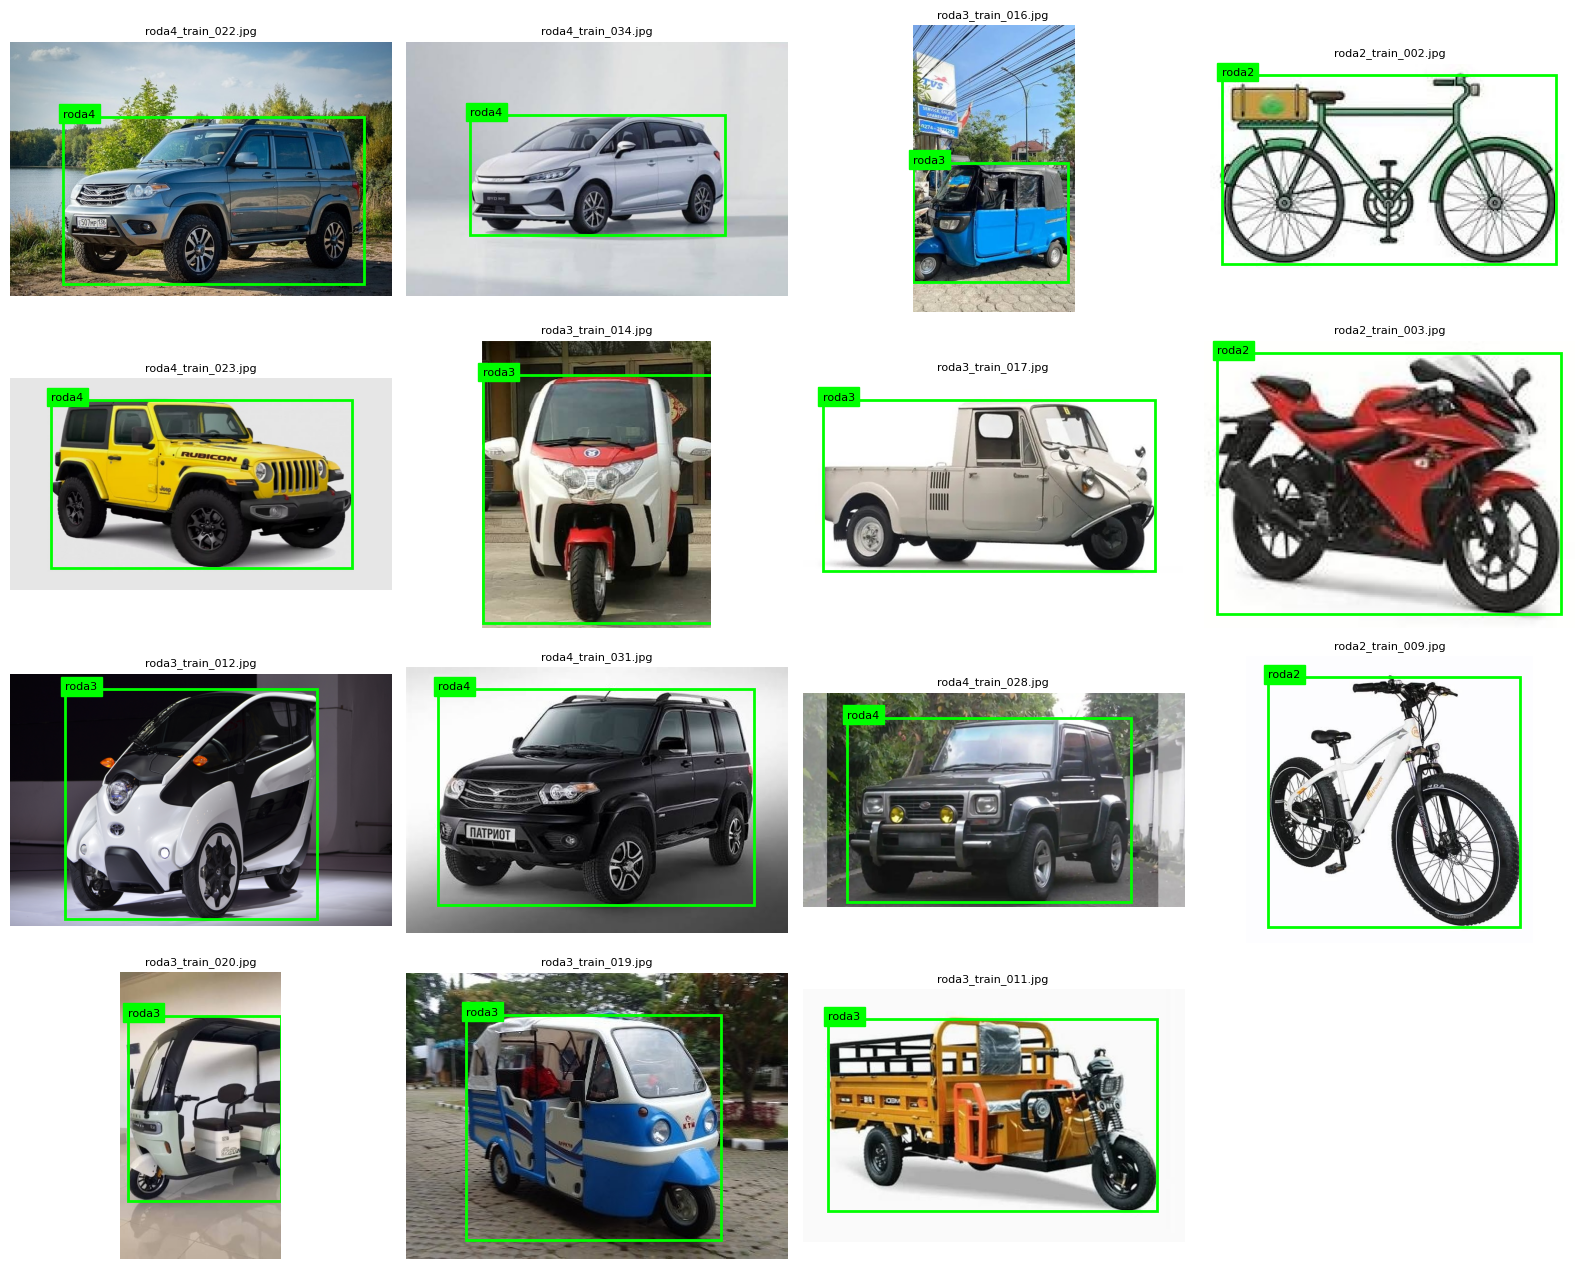

In [ ]:
# data.yaml
DATA_YAML = YOLO_DIR / "data.yaml"
with open(DATA_YAML, "w") as f:
    f.write(f"path: {YOLO_DIR.resolve()}\n")
    f.write("train: images/train\nval: images/val\ntest: images/test\n")
    f.write("names:\n" + "".join(f"  {i}: {n}\n" for i, n in enumerate(CLASS_NAMES)))
print(open(DATA_YAML).read())

# Visualisasi sampel label untuk dicek
def show_labels(split="train", n=15):
    files = sorted((YOLO_DIR / "images" / split).glob("*.jpg"))
    files = random.sample(files, min(n, len(files)))
    cols = 4; rows = int(np.ceil(len(files) / cols))
    plt.figure(figsize=(4 * cols, 3.2 * rows))
    for k, p in enumerate(files):
        im = np.array(Image.open(p)); H, W = im.shape[:2]
        ax = plt.subplot(rows, cols, k + 1); ax.imshow(im); ax.axis("off")
        lab = YOLO_DIR / "labels" / split / (p.stem + ".txt")
        for line in open(lab):
            c, x, y, w, h = line.split(); c = int(c); x, y, w, h = map(float, (x, y, w, h))
            ax.add_patch(plt.Rectangle(((x - w / 2) * W, (y - h / 2) * H), w * W, h * H, fill=False, color="lime", lw=2))
            ax.text((x - w / 2) * W, (y - h / 2) * H, CLASS_NAMES[c], color="black", backgroundcolor="lime", fontsize=8)
        ax.set_title(p.name, fontsize=8)
    plt.tight_layout(); plt.show()

show_labels("train")

> **Opsional tapi sangat disarankan:** jika label otomatis kurang tepat, koreksi di Roboflow/CVAT/LabelImg, ekspor format *YOLO*, lalu ganti isi folder `labels/` di `yolo_dataset`. Sisa notebook tidak perlu diubah.

## 3. Training YOLOv8 dan YOLOv11
Dataset sangat kecil (puluhan gambar), jadi dipakai model kecil (`s`), pretrained COCO, dan augmentasi yang cukup kuat. Ubah ke `n` (lebih ringan) atau `m` jika diperlukan.

In [ ]:
MODELS = {"yolov8s": "yolov8s.pt", "yolo11s": "yolo11s.pt"}
EPOCHS, IMGSZ, BATCH = 10, 640, 8
WORKERS = 0 if os.name == "nt" else 2   # di Windows, workers=0 menghindari error multiprocessing di notebook

best_weights = {}
for name, weights in MODELS.items():
    print(f"\n===== Training {name} =====")
    model = YOLO(weights)
    res = model.train(
        data=str(DATA_YAML), epochs=EPOCHS, imgsz=IMGSZ, batch=BATCH,
        patience=30, seed=SEED, workers=WORKERS, pretrained=True,
        project=str(WORK / "runs"), name=name, exist_ok=True, plots=True,
        # augmentasi (dataset kecil)
        mosaic=1.0, close_mosaic=10, mixup=0.1, fliplr=0.5, degrees=10,
        translate=0.1, scale=0.5, hsv_h=0.015, hsv_s=0.6, hsv_v=0.4,
    )
    best_weights[name] = Path(res.save_dir) / "weights" / "best.pt"
    print(name, "->", best_weights[name])


===== Training yolov8s =====
Ultralytics 8.4.215 🚀 Python-3.13.18 torch-2.14.1+cpu CPU (Intel Xeon CPU @ 2.20GHz)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/work_yolo/yolo_dataset/data.yaml, degrees=10, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=10, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.6, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.1, mode=train, model=yolov8s.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=yolov8s, nbs=64, nm

## 4. Evaluasi & perbandingan model

In [ ]:
rows = []
for name, w in best_weights.items():
    m = YOLO(str(w))
    for split in ["val", "test"]:
        r = m.val(data=str(DATA_YAML), split=split, imgsz=IMGSZ, plots=False, verbose=False,
                  project=str(WORK / "runs"), name=f"{name}_eval_{split}", exist_ok=True)
        rows.append(dict(model=name, split=split,
                         precision=r.box.mp, recall=r.box.mr, mAP50=r.box.map50, mAP50_95=r.box.map))
compare = pd.DataFrame(rows).round(3)
compare

Ultralytics 8.4.215 🚀 Python-3.13.18 torch-2.14.1+cpu CPU (Intel Xeon CPU @ 2.20GHz)
Model summary (fused): 72 layers, 11,126,745 parameters, 0 gradients, 28.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1184.1±748.5 MB/s, size: 64.6 KB)
val: Scanning /content/work_yolo/yolo_dataset/labels/val.cache... 8 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 8/8 1.9Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 1/1 7.7s/it 7.7s
                   all          8         10      0.517      0.684      0.614      0.361
Speed: 1.9ms preprocess, 700.5ms inference, 0.0ms loss, 253.6ms postprocess per image
Ultralytics 8.4.215 🚀 Python-3.13.18 torch-2.14.1+cpu CPU (Intel Xeon CPU @ 2.20GHz)
Model summary (fused): 72 layers, 11,126,745 parameters, 0 gradients, 28.4 GFLOPs
WARNING ⚠️ val: Slow image access detected (ping: 0.0±0.0 ms, read: 26.7±16.4 MB/s, size: 64.1 KB). Use local storage instead of remote/mounted 

,model,split,precision,recall,mAP50,mAP50_95
0,yolov8s,val,0.517,0.684,0.614,0.361
1,yolov8s,test,0.567,0.564,0.431,0.231
2,yolo11s,val,0.452,0.994,0.719,0.383
3,yolo11s,test,0.266,0.614,0.421,0.246


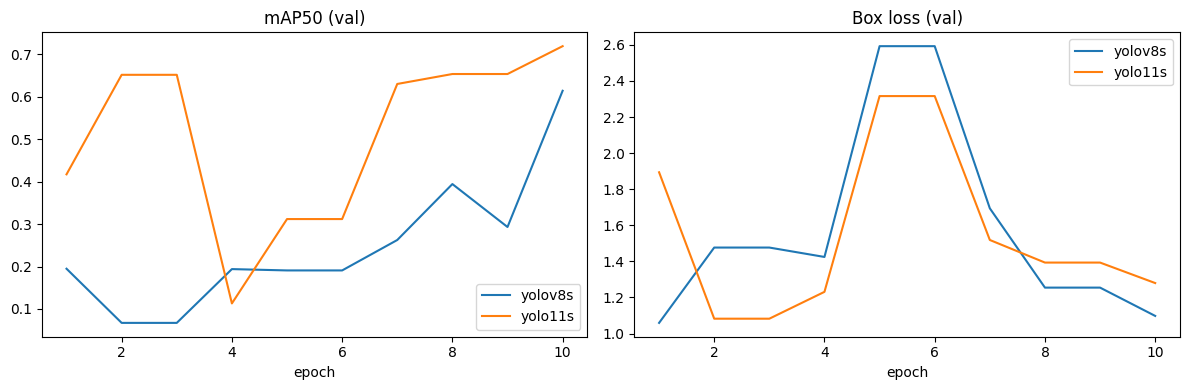

In [ ]:
# Kurva training (results.csv) kedua model
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for name in MODELS:
    df = pd.read_csv(WORK / "runs" / name / "results.csv"); df.columns = df.columns.str.strip()
    axes[0].plot(df["epoch"], df["metrics/mAP50(B)"], label=name)
    axes[1].plot(df["epoch"], df["val/box_loss"], label=name)
axes[0].set_title("mAP50 (val)"); axes[1].set_title("Box loss (val)")
for a in axes: a.set_xlabel("epoch"); a.legend()
plt.tight_layout(); plt.show()

## 5. Prediksi pada gambar `Testing`

Results saved to /content/work_yolo/predict/yolov8s


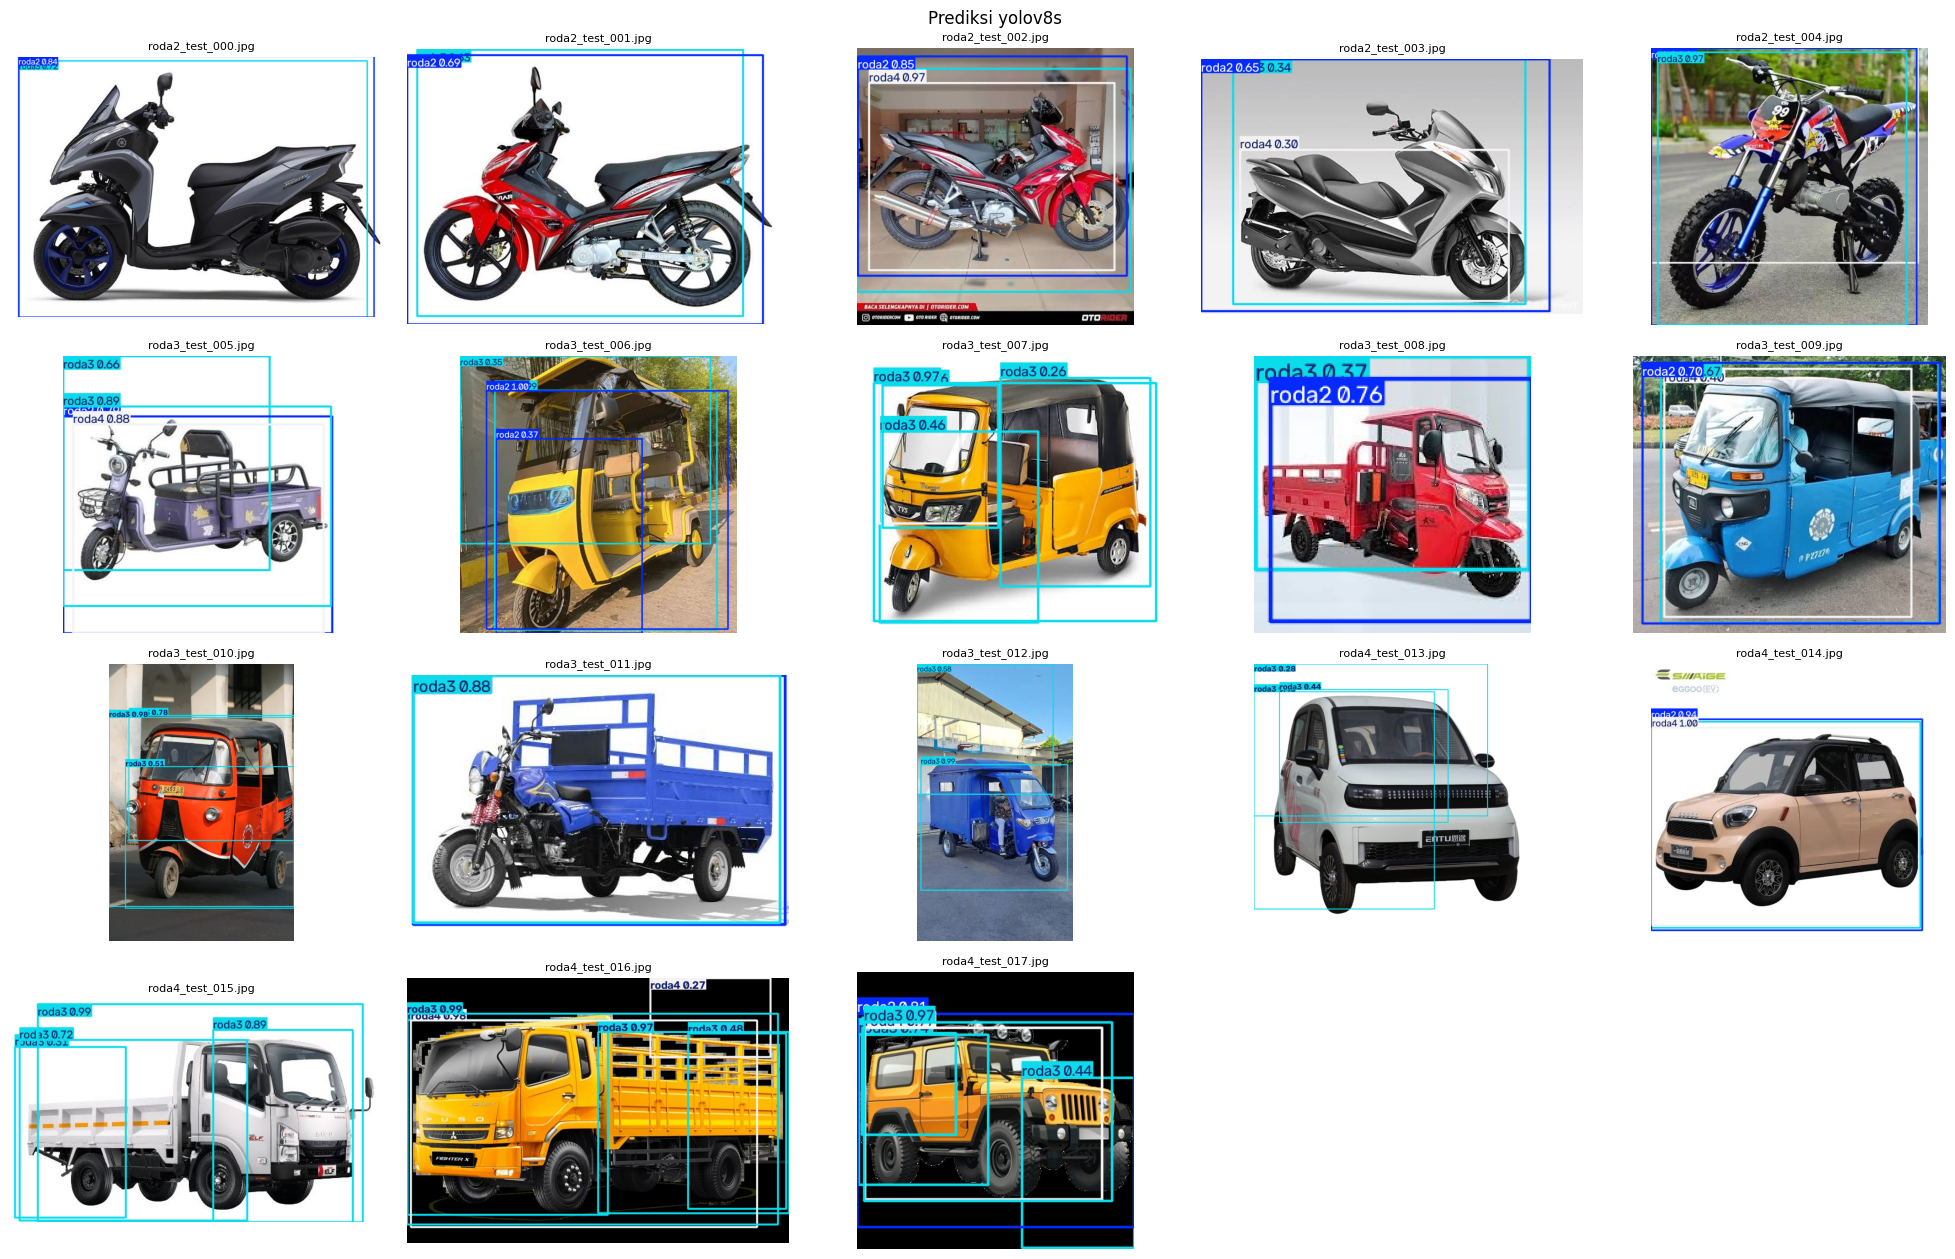

Hasil tersimpan di: /content/work_yolo/predict/yolov8s
Results saved to /content/work_yolo/predict/yolo11s


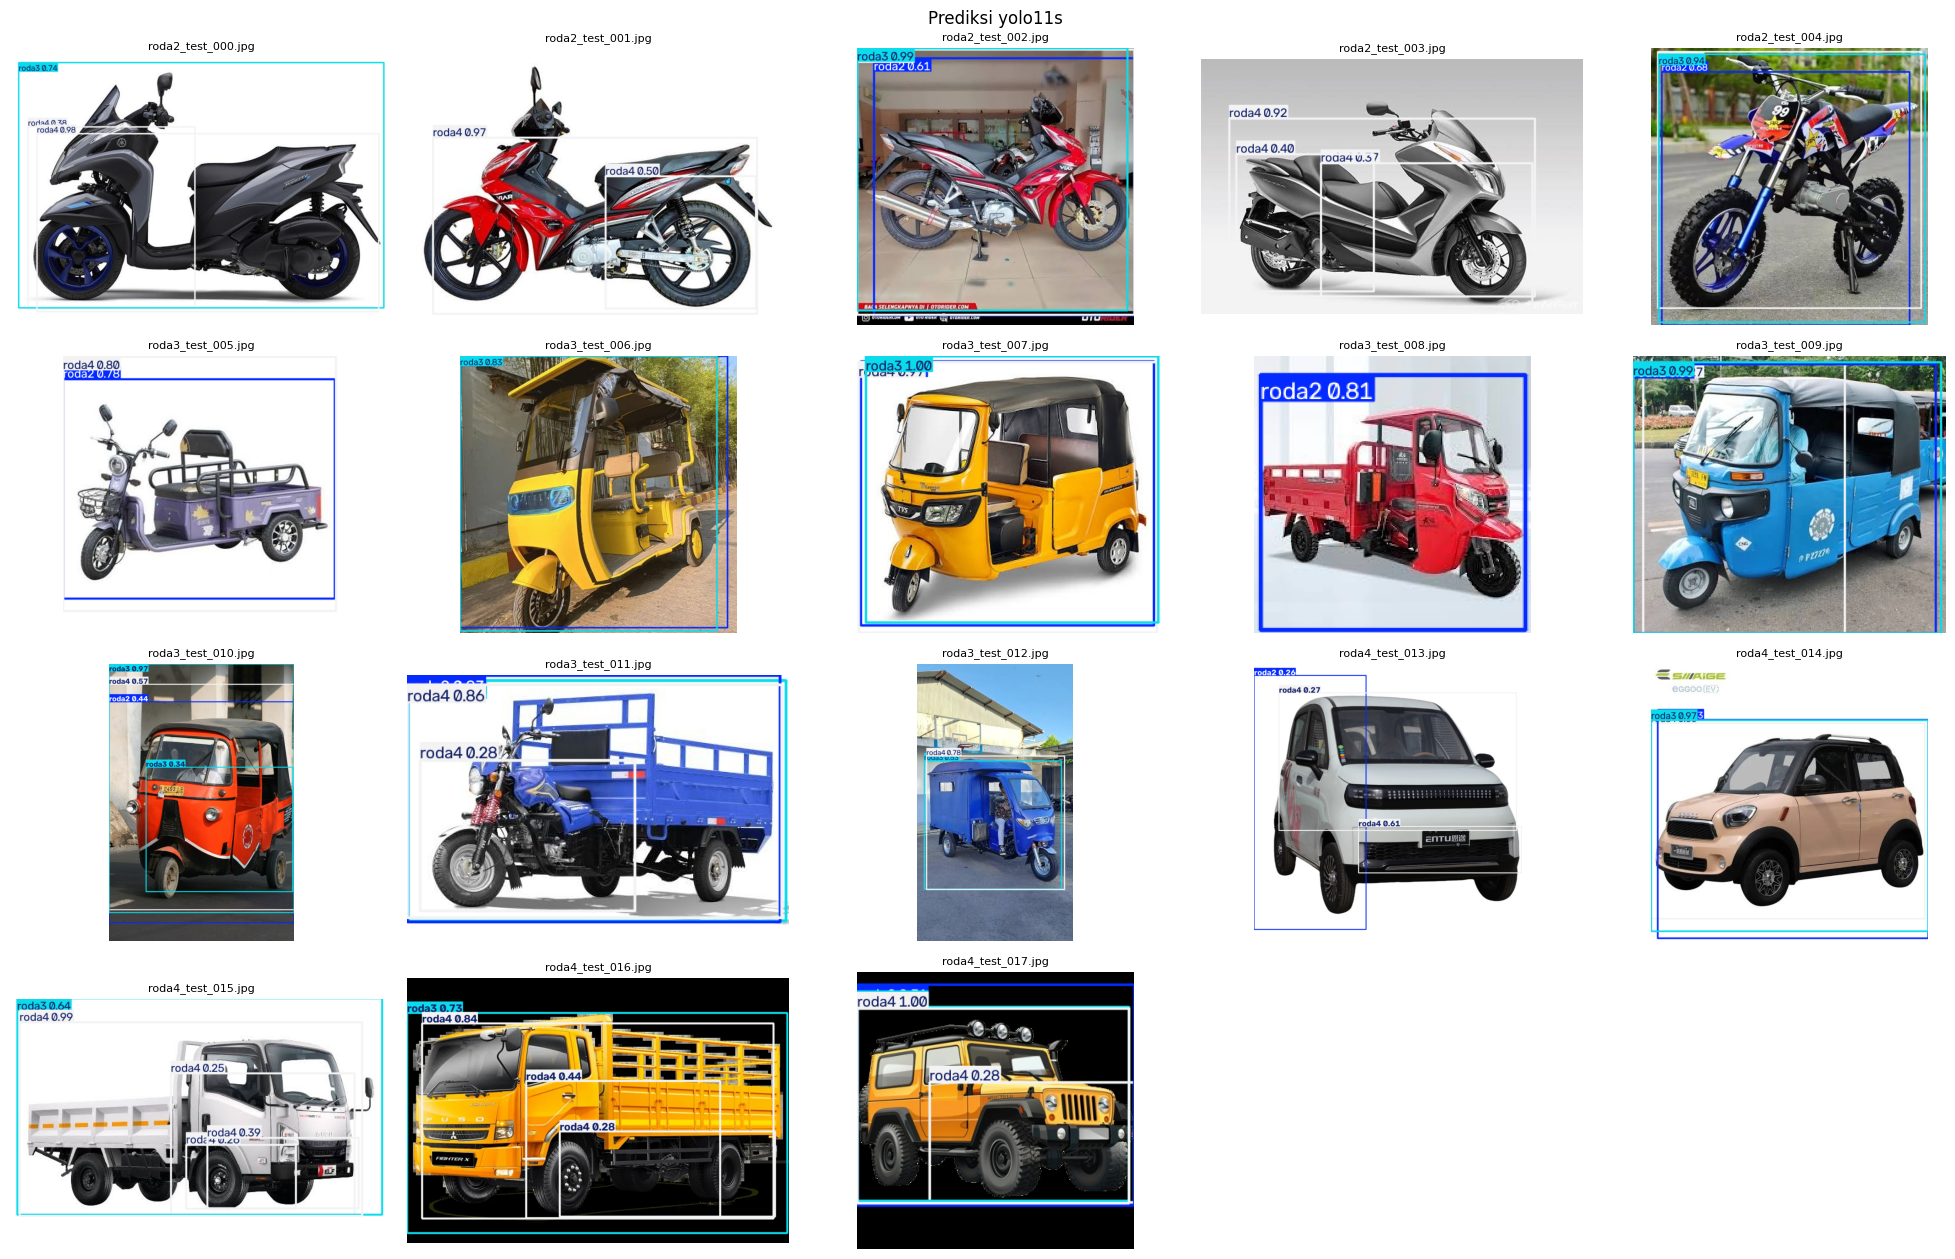

Hasil tersimpan di: /content/work_yolo/predict/yolo11s


In [ ]:
test_imgs = sorted((YOLO_DIR / "images" / "test").glob("*.jpg"))
for name, w in best_weights.items():
    m = YOLO(str(w))
    results = m.predict([str(p) for p in test_imgs], conf=0.25, imgsz=IMGSZ, verbose=False,
                        save=True, project=str(WORK / "predict"), name=name, exist_ok=True)
    cols = 5; rows_n = int(np.ceil(len(results) / cols))
    plt.figure(figsize=(4 * cols, 3.2 * rows_n))
    for k, r in enumerate(results):
        ax = plt.subplot(rows_n, cols, k + 1); ax.imshow(r.plot()[..., ::-1]); ax.axis("off")
        ax.set_title(Path(r.path).name, fontsize=8)
    plt.suptitle(f"Prediksi {name}"); plt.tight_layout(); plt.show()
    print("Hasil tersimpan di:", WORK / "predict" / name)

## 6. (Opsional) Export & inferensi pada gambar/video sendiri

In [ ]:
best_name = compare[compare.split == "test"].sort_values("mAP50_95", ascending=False).iloc[0].model
print("Model terbaik di test:", best_name)
final = YOLO(str(best_weights[best_name]))
final.export(format="onnx")            # juga bisa: 'torchscript', 'tflite', 'engine'

# Contoh pemakaian:
# final.predict("gambar_saya.jpg", conf=0.25, save=True)
# final.predict("video_saya.mp4", conf=0.25, save=True)
# final.predict(source=0, show=True)   # webcam

Model terbaik di test: yolo11s
Ultralytics 8.4.215 🚀 Python-3.13.18 torch-2.14.1+cpu CPU (Intel Xeon CPU @ 2.20GHz)
💡 ProTip: Export to OpenVINO format for best performance on Intel hardware. Learn more at https://docs.ultralytics.com/integrations/openvino
YOLO11s summary (fused): 100 layers, 9,413,961 parameters, 0 gradients, 21.4 GFLOPs

PyTorch: starting from '/content/work_yolo/runs/yolo11s/weights/best.pt' with input shape (1, 3, 640, 640) BCHW and output shape(s) (1, 7, 8400) (18.3 MB)
requirements: Ultralytics requirements ['onnx>=1.12.0,<2.0.0', 'onnxruntime', 'onnxslim>=0.1.82'] not found, attempting AutoUpdate...
Using Python 3.13.18 environment at: /usr
Resolved 12 packages in 480ms
Prepared 4 packages in 886ms
Installed 4 packages in 45ms
 + colorama==0.4.6
 + onnx==1.23.2
 + onnxruntime==1.32.0
 + onnxslim==0.1.99

requirements: AutoUpdate success ✅ 1.9s
WARNING ⚠️ requirements: Restart runtime or rerun command for updates to take effect


ONNX: starting export with onnx 1

'/content/work_yolo/runs/yolo11s/weights/best.onnx'